# 03 – Chọn 5000 mẫu cho hierarchical clustering

**Vì sao phải lấy mẫu?** Hierarchical clustering cần ma trận khoảng cách n×n (bộ nhớ ~ n², thời gian ~ n²–n³). Với hàng chục nghìn track (dataset gốc có ~28,000 `track_id`, sau preprocessing còn ít hơn), ma trận rút gọn lên cỡ hàng trăm triệu phần tử (vài GB) và rất chậm; với 5000 track chỉ còn ~12,5 triệu phần tử (~100 MB).

**Mục tiêu:** mẫu 5000 dòng phải giữ "tinh thần" của dataset gốc:
1. phân bố của các audio feature (kể cả các giá trị ngoại lai),
2. tỉ lệ thể loại (`playlist_genre`, `playlist_subgenre`),
3. mối tương quan giữa các feature.

**Quy trình**
1. Đọc `spotify_songs_clean.csv` (đầu ra của 02), chỉ giữ 14 cột cần thiết.
2. Giữ nguyên outlier (không loại, không cắt).
3. Lấy mẫu phân tầng theo `playlist_subgenre`, số điểm mỗi tầng tỉ lệ thuận với kích thước tầng.
4. Kiểm tra độ đại diện (KS, tỉ lệ genre, tương quan, tỉ lệ outlier).
5. Kiểm tra độ ổn định: nhiều seed, so với lấy mẫu ngẫu nhiên thường, thử nhiều kích thước mẫu.
6. Xuất mẫu.

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from IPython.display import display

DATA_DIR = Path("../data/processed")
IN_CSV   = DATA_DIR / "spotify_songs_clean.csv"      # đầu ra của 02_preprocessing
OUT_DIR  = Path("../data/samples/sampling")
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_SAMPLE   = 5000
SEED       = 42
STRATA_COL = "playlist_subgenre"        # cột dùng để phân tầng

ID_COL     = "track_id"
LABEL_COLS = ["playlist_genre", "playlist_subgenre"]
FEATURES   = ["danceability", "energy", "key", "loudness", "mode", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
KEEP_COLS  = [ID_COL] + LABEL_COLS + FEATURES

KS_THRESHOLD = 0.03                     # ngưỡng chấp nhận cho KS statistic (xem phần 3)

## 1. Đọc dữ liệu và chọn cột

Giữ 14 cột:

| Nhóm | Cột | Vai trò |
|---|---|---|
| Định danh | `track_id` | khóa của từng bài, dùng để truy ngược về dataset gốc |
| Nhãn | `playlist_genre`, `playlist_subgenre` | **không** đưa vào clustering; dùng để phân tầng lấy mẫu và để diễn giải cụm sau này |
| Đặc trưng | 11 audio feature (`danceability` … `tempo`) | đầu vào của clustering |

Các cột còn lại (`track_name`, `track_artist`, `track_popularity`, `duration_ms`, thông tin album và playlist...) bị bỏ vì không thuộc không gian đặc trưng đã chọn.

In [17]:
df = pd.read_csv(IN_CSV, usecols=KEEP_COLS)[KEEP_COLS]

assert df[ID_COL].is_unique, "track_id phải duy nhất (kết quả của 02)"
assert df.isna().sum().sum() == 0, "còn NaN -> chạy lại 02"

print(f"{len(df):,} track, {df.shape[1]} cột")
display(df.head())
display(df[FEATURES].describe().T)

23,370 track, 14 cột


,track_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,6f807x0ima9a1j3VPbc7VN,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036
1,0r7CVbZTWZgbTCYdfa2P31,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972
2,1z1Hg7Vb0AhHDiEmnDE79l,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008
3,75FpbthrwQmzHlBJLuGdC7,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956
4,1e8PAfcKUYoKkxPhrHqw4x,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976


,count,mean,std,min,25%,50%,75%,max
danceability,23370.0,0.657441,0.143387,0.000000,0.56700,0.673000,0.76100,0.983
energy,23370.0,0.696145,0.184291,0.000175,0.57700,0.719000,0.84100,1.000
key,23370.0,5.366367,3.621397,0.000000,2.00000,6.000000,9.00000,11.000
loudness,23370.0,-6.732791,3.000036,-46.448000,-8.17875,-6.195500,-4.67100,-0.046
mode,23370.0,0.555584,0.496911,0.000000,0.00000,1.000000,1.00000,1.000
speechiness,23370.0,0.109697,0.103488,0.000000,0.04170,0.064100,0.13700,0.918
acousticness,23370.0,0.181310,0.226078,0.000000,0.01450,0.082400,0.26900,0.994
instrumentalness,23370.0,0.101611,0.245416,0.000000,0.00000,0.000025,0.00967,0.994
liveness,23370.0,0.188941,0.152795,0.000000,0.09340,0.126000,0.24300,0.994
valence,23370.0,0.494699,0.233602,0.000000,0.31300,0.493000,0.67700,0.984


## 2. Outlier: giữ nguyên

Theo yêu cầu, **không loại và không cắt (clip) bất kỳ outlier nào**. Dưới đây chỉ *đo* tỉ lệ outlier theo quy tắc IQR (ngoài [Q1 − 1,5·IQR, Q3 + 1,5·IQR]) để biết chúng nằm ở đâu và để so sánh với mẫu ở phần 4.

Lưu ý khi sang bước clustering (không xử lý ở notebook này):
- Hierarchical clustering nhạy với outlier, đặc biệt với `single` / `average` linkage (hiện tượng chaining), còn `ward` ít bị hơn nhưng vẫn bị kéo.
- Khi chuẩn hóa, có thể so sánh `StandardScaler` với `RobustScaler` (dùng median/IQR nên ít bị outlier kéo hơn).
- `key` và `mode` là biến rời rạc, nên cân nhắc khi dùng khoảng cách Euclid.

In [18]:
def iqr_outlier_rate(frame, ref=None):
    """Tỉ lệ điểm ngoài [Q1-1.5*IQR, Q3+1.5*IQR]. Ngưỡng lấy từ `ref` (mặc định chính frame)."""
    ref = frame if ref is None else ref
    q1, q3 = ref[FEATURES].quantile(0.25), ref[FEATURES].quantile(0.75)
    iqr = q3 - q1
    out = (frame[FEATURES] < q1 - 1.5 * iqr) | (frame[FEATURES] > q3 + 1.5 * iqr)
    return out.mean()

outlier_full = iqr_outlier_rate(df)
display((outlier_full * 100).round(2).rename("tỉ lệ outlier toàn bộ (%)").to_frame())

,tỉ lệ outlier toàn bộ (%)
danceability,1.00
energy,0.83
key,0.00
loudness,3.03
mode,0.00
speechiness,9.17
acousticness,6.43
instrumentalness,21.71
liveness,5.75
valence,0.00


## 3. Lấy mẫu phân tầng theo `playlist_subgenre`

**Vì sao phân tầng?** Lấy ngẫu nhiên đơn giản có thể làm lệch tỉ lệ các subgenre nhỏ. Phân tầng bảo đảm mỗi subgenre có số điểm đúng bằng tỉ lệ của nó trong dataset gốc.

**Phân bổ:** với tầng *k* có kích thước *n_k*, hạn ngạch là *N · n_k / tổng*. Phần nguyên được cấp trước, phần dư được cấp lần lượt cho các tầng có phần thập phân lớn nhất (largest remainder) để tổng đúng bằng `N_SAMPLE`.

**Vì sao không làm cách khác?**
- Lấy 5000 dòng đầu: file xếp theo playlist nên mẫu lệch genre nặng.
- Lấy theo popularity cao nhất: lệch về nhạc phổ biến.
- Chia đều mỗi genre: làm sai phân bố gốc.
- Chọn các điểm "đa dạng nhất" (farthest-point): kéo outlier vào mẫu quá mức.

**Tiêu chí kiểm tra đại diện** (phần 4):
- KS statistic của từng feature (khoảng cách lớn nhất giữa hai hàm phân phối tích lũy): mục tiêu < `KS_THRESHOLD` = 0,03. Mình dùng độ lớn KS thay cho p-value vì với n lớn p-value rất dễ gây hiểu nhầm.
- Chênh lệch tỉ lệ genre / subgenre: gần 0 (chỉ còn sai số làm tròn).
- Chênh lệch ma trận tương quan: nhỏ.

In [19]:
def allocate(counts, n):
    """Chia n điểm cho các tầng tỉ lệ theo `counts` (largest remainder), tổng đúng bằng n."""
    quota = counts * n / counts.sum()
    base = np.floor(quota).astype(int)
    rest = int(n - base.sum())
    top = (quota - base).sort_values(ascending=False).index[:rest]
    base.loc[top] += 1
    assert base.sum() == n and (base <= counts).all()
    return base


def stratified_sample(frame, n, seed, col=STRATA_COL):
    alloc = allocate(frame[col].value_counts(), n)
    parts = [g.sample(n=int(alloc[k]), random_state=seed) for k, g in frame.groupby(col)]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


def _prop(frame, col, index=None):
    p = frame[col].value_counts(normalize=True)
    return p if index is None else p.reindex(index, fill_value=0)


def evaluate(full, samp):
    ks = pd.Series({c: ks_2samp(full[c], samp[c]).statistic for c in FEATURES})
    diff = {}
    for col in LABEL_COLS:
        pf = _prop(full, col)
        diff[col] = (_prop(samp, col, pf.index) - pf).abs().max()
    corr = (full[FEATURES].corr() - samp[FEATURES].corr()).abs().to_numpy().max()
    return {"ks_max": ks.max(), "genre_diff_max": diff["playlist_genre"],
            "subgenre_diff_max": diff["playlist_subgenre"], "corr_diff_max": corr}, ks

In [20]:
strata = df[STRATA_COL].value_counts().rename("n_gốc").to_frame()
strata["hạn_ngạch"] = allocate(df[STRATA_COL].value_counts(), N_SAMPLE)
strata["tỉ_lệ_gốc (%)"] = (strata["n_gốc"] / len(df) * 100).round(2)
display(strata)
print(f"Tầng nhỏ nhất: {strata['n_gốc'].min():,} track gốc -> {strata['hạn_ngạch'].min()} điểm trong mẫu")

,n_gốc,hạn_ngạch,tỉ_lệ_gốc (%)
playlist_subgenre,,,
indie poptimism,1427,305,6.11
electro house,1374,294,5.88
progressive electro house,1297,277,5.55
hip hop,1230,263,5.26
dance pop,1215,260,5.20
trap,1186,254,5.07
neo soul,1173,251,5.02
southern hip hop,1120,240,4.79
tropical,1104,236,4.72


Tầng nhỏ nhất: 504 track gốc -> 108 điểm trong mẫu


In [21]:
sample = stratified_sample(df, N_SAMPLE, SEED)

assert len(sample) == N_SAMPLE and sample[ID_COL].is_unique
print(f"Mẫu: {len(sample):,} dòng ({len(sample) / len(df):.1%} dataset)")

Mẫu: 5,000 dòng (21.4% dataset)


## 4. Kiểm tra mẫu có đại diện không

So sánh mẫu với toàn bộ dataset (sau preprocessing): KS từng feature, tỉ lệ genre, tương quan, và tỉ lệ outlier (xem outlier có bị mất hoặc bị nhân lên không).

,giá trị
ks_max,0.0203
genre_diff_max,0.0002
subgenre_diff_max,0.0001
corr_diff_max,0.0333


KS lớn nhất = 0.0203 (tempo) | ngưỡng 0.03 -> ĐẠT


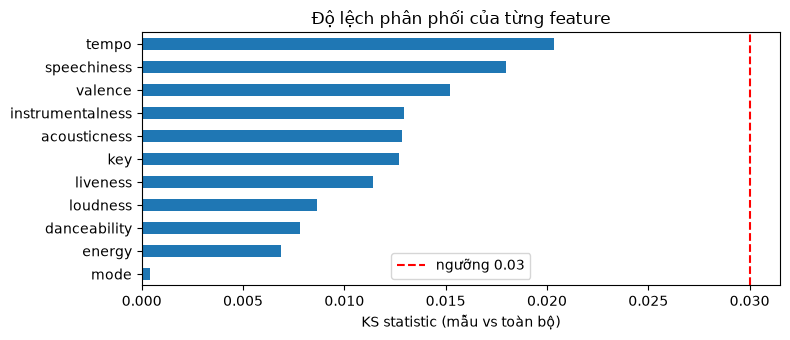

In [22]:
summary, ks = evaluate(df, sample)
display(pd.Series(summary, name="giá trị").round(4).to_frame())
print(f"KS lớn nhất = {ks.max():.4f} ({ks.idxmax()}) | ngưỡng {KS_THRESHOLD} -> "
      f"{'ĐẠT' if ks.max() < KS_THRESHOLD else 'CHƯA ĐẠT'}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ks.sort_values().plot.barh(ax=ax)
ax.axvline(KS_THRESHOLD, color="red", ls="--", label=f"ngưỡng {KS_THRESHOLD}")
ax.set_xlabel("KS statistic (mẫu vs toàn bộ)")
ax.set_title("Độ lệch phân phối của từng feature")
ax.legend()
plt.tight_layout()
plt.show()

,toàn bộ (%),mẫu (%)
playlist_genre,,
rap,19.57,19.58
edm,19.45,19.44
pop,18.70,18.68
latin,15.01,15.02
r&b,14.83,14.84
rock,12.43,12.44


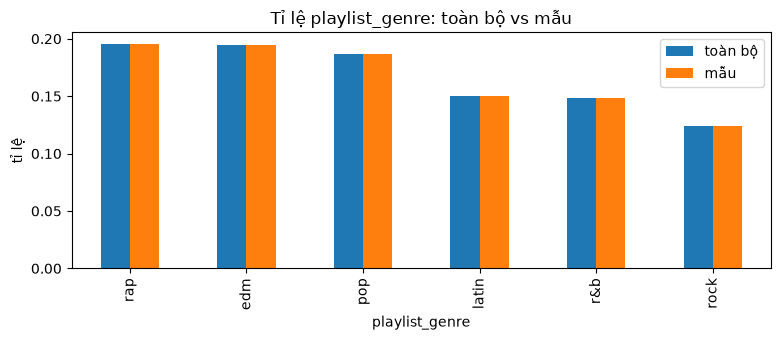

In [23]:
genre = pd.DataFrame({
    "toàn bộ": _prop(df, "playlist_genre"),
    "mẫu": _prop(sample, "playlist_genre"),
})
display((genre * 100).round(2).add_suffix(" (%)"))
genre.plot.bar(figsize=(8, 3.5), title="Tỉ lệ playlist_genre: toàn bộ vs mẫu")
plt.ylabel("tỉ lệ")
plt.tight_layout()
plt.show()

In [24]:
# Outlier: dùng NGƯỠNG của toàn bộ dataset để đo trên mẫu -> kiểm tra outlier không bị mất / nhân lên
outlier_cmp = pd.DataFrame({
    "toàn bộ": iqr_outlier_rate(df),
    "mẫu": iqr_outlier_rate(sample, ref=df),
})
outlier_cmp["chênh lệch"] = outlier_cmp["mẫu"] - outlier_cmp["toàn bộ"]
display((outlier_cmp * 100).round(2).add_suffix(" (%)"))

# Giá trị cực trị: mẫu không nhất thiết chứa đúng min/max của toàn bộ (điều bình thường khi lấy mẫu)
extremes = pd.concat({"min_toàn_bộ": df[FEATURES].min(), "min_mẫu": sample[FEATURES].min(),
                      "max_toàn_bộ": df[FEATURES].max(), "max_mẫu": sample[FEATURES].max()}, axis=1)
display(extremes)

,toàn bộ (%),mẫu (%),chênh lệch (%)
danceability,1.00,0.92,-0.08
energy,0.83,0.88,0.05
key,0.00,0.00,0.00
loudness,3.03,3.04,0.01
mode,0.00,0.00,0.00
speechiness,9.17,8.86,-0.31
acousticness,6.43,6.98,0.55
instrumentalness,21.71,21.12,-0.59
liveness,5.75,4.64,-1.11
valence,0.00,0.00,0.00


,min_toàn_bộ,min_mẫu,max_toàn_bộ,max_mẫu
danceability,0.000000,0.130000,0.983,0.979
energy,0.000175,0.038900,1.000,1.000
key,0.000000,0.000000,11.000,11.000
loudness,-46.448000,-46.448000,-0.046,-0.046
mode,0.000000,0.000000,1.000,1.000
speechiness,0.000000,0.023500,0.918,0.853
acousticness,0.000000,0.000002,0.994,0.994
instrumentalness,0.000000,0.000000,0.994,0.994
liveness,0.000000,0.015800,0.994,0.983
valence,0.000000,0.000010,0.984,0.978


## 5. Độ ổn định của việc lấy mẫu

**5a. Nhiều seed, so với lấy ngẫu nhiên đơn giản (SRS).** Nếu phân tầng tốt hơn SRS thì tỉ lệ genre/subgenre lệch ít hơn rõ rệt, còn KS tương đương hoặc nhỉnh hơn một chút. Nếu KS dao động ít giữa các seed thì kết quả không phụ thuộc may rủi của một lần lấy mẫu.

**5b. Nhiều kích thước mẫu.** Dùng để trả lời "có nhất thiết 5000 không". Nếu các chỉ số gần như không cải thiện thêm khi tăng N thì 5000 là đủ; ngược lại nếu 3000 đã cho chỉ số tương tự thì có thể giảm để chạy nhanh hơn.

In [25]:
N_SEEDS = 20
rows = []
for seed in range(N_SEEDS):
    strat, _ = evaluate(df, stratified_sample(df, N_SAMPLE, seed))
    srs, _   = evaluate(df, df.sample(n=N_SAMPLE, random_state=seed))
    rows.append({"seed": seed, "cách": "phân tầng", **strat})
    rows.append({"seed": seed, "cách": "ngẫu nhiên (SRS)", **srs})

seeds_df = pd.DataFrame(rows)
display(seeds_df.groupby("cách")[["ks_max", "genre_diff_max", "subgenre_diff_max", "corr_diff_max"]]
        .agg(["mean", "max"]).round(4))

ks_max         genre_diff_max         subgenre_diff_max  \
                    mean     max           mean     max              mean   
cách                                                                        
ngẫu nhiên (SRS)  0.0161  0.0241         0.0080  0.0123            0.0056   
phân tầng         0.0155  0.0230         0.0002  0.0002            0.0001   

                         corr_diff_max          
                     max          mean     max  
cách                                            
ngẫu nhiên (SRS)  0.0075        0.0339  0.0465  
phân tầng         0.0001        0.0304  0.0429

,ks_max,genre_diff_max,subgenre_diff_max,corr_diff_max
N,,,,
2000,0.0313,0.0003,0.0003,0.0572
3000,0.0271,0.0002,0.0002,0.0382
5000,0.0203,0.0002,0.0001,0.0333
8000,0.0140,0.0001,0.0001,0.0240
10000,0.0116,0.0001,0.0001,0.0174


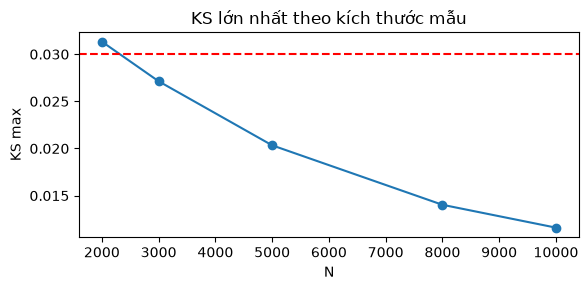

In [26]:
rows = []
for n in [2000, 3000, 5000, 8000, 10000]:
    res, _ = evaluate(df, stratified_sample(df, n, SEED))
    rows.append({"N": n, **res})
sizes_df = pd.DataFrame(rows).set_index("N")
display(sizes_df.round(4))

sizes_df["ks_max"].plot(marker="o", figsize=(6, 3), title="KS lớn nhất theo kích thước mẫu")
plt.axhline(KS_THRESHOLD, color="red", ls="--")
plt.ylabel("KS max")
plt.tight_layout()
plt.show()

## 6. Xuất kết quả

- `spotify_sample_5000.csv`: 5000 mẫu (14 cột) để clustering.
- `spotify_features_all.csv`: toàn bộ dataset với cùng 14 cột. Sau khi có cụm trên mẫu, bạn có thể gán các track còn lại vào cụm gần nhất (centroid hoặc kNN) để mở rộng kết quả ra toàn bộ.

Bước tiếp theo (04): chuẩn hóa feature, chọn linkage và metric, vẽ dendrogram (cắt bớt), chọn số cụm bằng silhouette / cophenetic correlation, diễn giải cụm bằng `playlist_genre` / `playlist_subgenre`.

In [27]:
sample_path = OUT_DIR / f"spotify_sample_{N_SAMPLE}.csv"
all_path    = OUT_DIR / "spotify_features_all.csv"

sample.to_csv(sample_path, index=False, encoding="utf-8")
df.to_csv(all_path, index=False, encoding="utf-8")

print(f"Đã xuất mẫu:        {sample_path.resolve()}  ({len(sample):,} dòng)")
print(f"Đã xuất toàn bộ:    {all_path.resolve()}  ({len(df):,} dòng)")

Đã xuất mẫu:        C:\Users\PC\OneDrive\Documents\Personal_Archive\01_University\Semester_03\CS115_Mathematics_for_Computer_science\05_Project\Final_term_project\Spotify-mood-clustering\data\samples\sampling\spotify_sample_5000.csv  (5,000 dòng)
Đã xuất toàn bộ:    C:\Users\PC\OneDrive\Documents\Personal_Archive\01_University\Semester_03\CS115_Mathematics_for_Computer_science\05_Project\Final_term_project\Spotify-mood-clustering\data\samples\sampling\spotify_features_all.csv  (23,370 dòng)


In [28]:
import pandas as pd
samples = pd.read_csv("../data/samples/sampling/spotify_sample_5000.csv")
samples


,track_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,1K86gziny1mnNIisKBqzhH,rap,gangster rap,0.473,0.843,1,-5.981,1,0.2250,0.00345,0.000025,0.102,0.2400,71.647
1,5tw6ibIqJSd8eAW5G47wCr,latin,latin hip hop,0.666,0.905,0,-4.574,0,0.2110,0.11400,0.000000,0.202,0.7090,81.787
2,5xq7pQlWzS8MKCbeU6PVnI,latin,latin pop,0.770,0.804,9,-5.196,1,0.0296,0.17800,0.001650,0.154,0.8580,115.956
3,5dS2dvXVPe7AR6UwBpnomW,edm,electro house,0.587,0.920,0,-4.697,0,0.0914,0.09360,0.073000,0.185,0.3500,126.035
4,5X73AYzzEE5Di0JwcQKt9N,pop,dance pop,0.421,0.669,4,-4.724,1,0.1270,0.15100,0.000000,0.635,0.3260,175.788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0OWcpVA83HI8Pb5DybDuoX,rap,trap,0.882,0.777,5,-4.445,1,0.0504,0.35400,0.000000,0.135,0.5330,121.985
4996,183Klch3PBWLz2S6zNUVxR,rock,classic rock,0.510,0.893,9,-9.267,1,0.0342,0.00102,0.000058,0.201,0.9340,142.657
4997,33Pxmhfhvmkf8zSosr2tE5,r&b,new jack swing,0.911,0.913,6,-5.328,0,0.3240,0.18600,0.000000,0.501,0.8340,114.052
4998,4kHwYiQ6nDHgEBRSEdKLzH,edm,progressive electro house,0.715,0.569,0,-8.492,1,0.0571,0.10600,0.839000,0.273,0.5560,127.008
